# Notebook 01 — Multi-Cloud IaC to Unified Finding Schema

Builds a provenance-tracked corpus of cloud security findings across AWS, Azure and GCP by
scanning publicly archived vulnerable-by-design Infrastructure-as-Code, then normalising every
finding into the Unified Finding Schema.

**Runtime: CPU. No GPU needed. 15–20 minutes.**

Every record traces to a repository, commit SHA, file, line range, scanner and scanner version,
so the corpus is reproducible from a clean checkout.

### Fixes applied in this version

| Issue | Cause | Fix |
|---|---|---|
| Install failed | `checkov==3.3.8` pins `networkx<3` but the cell requested `>=3.0` | networkx removed; nothing here uses it |
| Feature extraction returned all-defaults | `--compact` strips the raw HCL that extraction reads | scans run without `--compact`, asserted afterwards |
| Manifest never written | `datetime` not imported in the export cell | all cells self-contained |
| Results lost on session end | outputs stayed in `/content` | everything mirrored to Google Drive as produced |


## 1 · Install


In [1]:
!pip -q install "pydantic>=2.0" checkov==3.3.8 2>&1 | tail -3
import subprocess
v = subprocess.run(["checkov","--version"], capture_output=True, text=True).stdout.strip()
print("checkov:", v)
assert v.startswith("3."), "checkov did not install correctly"

bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
google-cloud-bigquery 3.42.2 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
scikit-image 0.25.2 requires networkx>=3.0, but you have networkx 2.6.3 which is incompatible.
checkov: 3.3.8


## 2 · Workspace and Drive

Drive is mounted first so a permissions problem surfaces before any scanning work.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import collections, hashlib, json, os, shutil, subprocess, sys, zipfile

BASE = Path("/content/mcasm_project")
REPOS, SCANS, OUT, FIG = BASE/"repos", BASE/"scans", BASE/"ufs", BASE/"figures"
for p in (REPOS, SCANS, OUT, FIG): p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(BASE))

DRIVE = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mcasm_stage1"); DRIVE.mkdir(parents=True, exist_ok=True)
    print("Drive mirror:", DRIVE)
except Exception as e:
    print(f"Drive unavailable ({type(e).__name__}) — continuing without mirror")

def mirror(src, name):
    if DRIVE is None: return
    try:
        src = Path(src); dst = DRIVE/name; dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src, dst, dirs_exist_ok=True) if src.is_dir() else shutil.copy(src, dst)
        print(f"  mirrored -> {name}")
    except Exception as e:
        print(f"  mirror failed ({name}): {type(e).__name__}")

print("workspace:", BASE)

Mounted at /content/drive
Drive mirror: /content/drive/MyDrive/mcasm_stage1
workspace: /content/mcasm_project


## 3 · Install the mcasm package

Upload `mcasm.zip` (version 1.2 or later) via the Files pane when prompted.


In [3]:
pkg = Path("/content/mcasm.zip")
if not pkg.exists():
    from google.colab import files
    print("Upload mcasm.zip")
    files.upload()

assert pkg.exists(), "mcasm.zip not found at /content/mcasm.zip"
with zipfile.ZipFile(pkg) as z: z.extractall(BASE)

for m in [k for k in list(sys.modules) if k.startswith("mcasm")]: del sys.modules[m]
import mcasm
from mcasm.schema.ufs import UnifiedFinding, Provider, SCHEMA_VERSION
from mcasm.normalise.checkov_map import normalise_file, coverage_report
from mcasm.rank.baselines import (composite_reference_score, ssvc_classify,
                                  reference_rank, generate_justification, WEIGHTS)
print("mcasm", mcasm.__version__, "| UFS schema", SCHEMA_VERSION)
print("CRS weights (frozen a priori):", WEIGHTS)

mcasm 1.2.0 | UFS schema 1.0.0
CRS weights (frozen a priori): {'exposure': 0.3, 'identity': 0.25, 'data': 0.2, 'blast': 0.15, 'intel': 0.1}


## 4 · Clone source repositories

Six vulnerable-by-design repositories, each pinned to the commit actually used. These are the
sources named in the methodology chapter.

CNAPPgoat is cloned for its scenario taxonomy but produces no findings — it is written in
Pulumi (Go/YAML), which Checkov cannot parse. Recorded here so the omission is documented
rather than silent.


In [4]:
SOURCES = {
 "terragoat":      "https://github.com/bridgecrewio/terragoat.git",
 "awsgoat":        "https://github.com/ine-labs/AWSGoat.git",
 "azuregoat":      "https://github.com/ine-labs/AzureGoat.git",
 "gcpgoat":        "https://github.com/ine-labs/GCPGoat.git",
 "iam-vulnerable": "https://github.com/BishopFox/iam-vulnerable.git",
 "cnappgoat":      "https://github.com/ermetic-research/cnappgoat-scenarios.git",
}

provenance = {}
for name, url in SOURCES.items():
    dest = REPOS/name
    if not dest.exists():
        subprocess.run(["git","clone","--depth","1","-q",url,str(dest)], check=False)
    sha = subprocess.run(["git","-C",str(dest),"rev-parse","HEAD"],
                         capture_output=True, text=True).stdout.strip()
    tf = len(list(dest.rglob("*.tf"))) if dest.exists() else 0
    provenance[name] = {"url":url, "commit":sha, "terraform_files":tf}
    print(f"{name:16} {sha[:12] or 'CLONE FAILED':14} {tf:4} .tf files")

(BASE/"provenance.json").write_text(json.dumps(provenance, indent=2))
mirror(BASE/"provenance.json", "provenance.json")

terragoat        729f8da62c6a     47 .tf files
awsgoat          b24869ad455e      2 .tf files
azuregoat        b97045952e6d      1 .tf files
gcpgoat          44605c4bff4b      1 .tf files
iam-vulnerable   0f298666f9b7     59 .tf files
cnappgoat        c98acdac710f      0 .tf files
  mirrored -> provenance.json


## 5 · Scan

**`--compact` must not be used.** It strips `code_block`, the raw HCL that every structural
feature extractor reads. With it, the pipeline silently produces findings carrying zero
exposure, identity or data signal — it fails without erroring. An assertion below verifies
the HCL survived.


In [5]:
TARGETS = [
 ("terragoat_aws",   REPOS/"terragoat/terraform/aws"),
 ("terragoat_azure", REPOS/"terragoat/terraform/azure"),
 ("terragoat_gcp",   REPOS/"terragoat/terraform/gcp"),
 ("awsgoat",         REPOS/"awsgoat"),
 ("azuregoat",       REPOS/"azuregoat"),
 ("gcpgoat",         REPOS/"gcpgoat"),
 ("iam_vulnerable",  REPOS/"iam-vulnerable"),
 ("cnappgoat",       REPOS/"cnappgoat/scenarios"),
]

for label, path in TARGETS:
    if not Path(path).exists():
        print(f"{label:18} SKIP (not present)"); continue
    out = SCANS/f"{label}.json"
    if out.exists() and out.stat().st_size > 0:
        print(f"{label:18} cached"); continue
    subprocess.run(f'checkov -d "{path}" -o json --quiet > "{out}" 2>/dev/null',
                   shell=True, check=False)
    print(f"{label:18} {out.stat().st_size/1024:9.1f} KiB")

terragoat_aws         1546.2 KiB
terragoat_azure       1496.0 KiB
terragoat_gcp          305.2 KiB
awsgoat                966.8 KiB
azuregoat              225.4 KiB
gcpgoat                193.4 KiB
iam_vulnerable        1300.8 KiB
cnappgoat               88.3 KiB


In [6]:
# Verify the raw HCL survived — this is the --compact guard
def has_code_blocks(p):
    d = json.loads(Path(p).read_text())
    blocks = d if isinstance(d, list) else [d]
    for b in blocks:
        if b.get("check_type") != "terraform": continue
        for r in (b.get("results") or {}).get("failed_checks", [])[:20]:
            if r.get("code_block"): return True
    return False

checked = [(f.stem, has_code_blocks(f)) for f in sorted(SCANS.glob("*.json")) if f.stat().st_size > 0]
for name, ok in checked: print(f"  {name:18} raw HCL present: {ok}")
assert any(ok for _, ok in checked), "No scan retained code_block — was --compact used?"
print("\nHCL check passed. Feature extraction will work.")

  awsgoat            raw HCL present: True
  azuregoat          raw HCL present: True
  cnappgoat          raw HCL present: False
  gcpgoat            raw HCL present: True
  iam_vulnerable     raw HCL present: True
  terragoat_aws      raw HCL present: True
  terragoat_azure    raw HCL present: True
  terragoat_gcp      raw HCL present: True

HCL check passed. Feature extraction will work.


## 6 · Normalise to the Unified Finding Schema


In [7]:
REPO_OF = {"terragoat_aws":"terragoat","terragoat_azure":"terragoat","terragoat_gcp":"terragoat",
           "awsgoat":"awsgoat","azuregoat":"azuregoat","gcpgoat":"gcpgoat",
           "iam_vulnerable":"iam-vulnerable","cnappgoat":"cnappgoat"}

findings, coverage = [], {}
for label, _ in TARGETS:
    f = SCANS/f"{label}.json"
    if not f.exists() or f.stat().st_size == 0: continue
    repo = REPO_OF[label]
    got = list(normalise_file(
        f,
        source_repo=SOURCES[repo].replace("https://github.com/","").replace(".git",""),
        source_commit=provenance.get(repo,{}).get("commit")))
    coverage[label] = coverage_report(f)
    findings += got
    print(f"{label:18} {len(got):5} findings")

seen, unique = set(), []
for f in findings:
    if f.finding_id in seen: continue
    seen.add(f.finding_id); unique.append(f)
print(f"\n{len(findings)} -> {len(unique)} after deduplication")
findings = unique
assert findings, "no findings produced — check the scans"

terragoat_aws        215 findings
terragoat_azure      174 findings
terragoat_gcp         56 findings
awsgoat              215 findings
azuregoat             37 findings
gcpgoat               43 findings
iam_vulnerable       269 findings
cnappgoat              0 findings

1009 -> 1009 after deduplication


## 7 · Exploratory analysis

Three things determine whether this corpus can support the ranking task: provider balance,
feature density, and how concentrated the score ties are.


In [8]:
import pandas as pd, numpy as np

rows = []
for f in findings:
    s = ssvc_classify(f)
    rows.append({
      "finding_id":f.finding_id, "provider":f.provider.value, "service":f.service,
      "resource_type":f.resource_type, "resource_id":f.resource_id,
      "check_id":f.check_id, "source_repo":f.source_repo,
      "internet_reachable":f.exposure.internet_reachable,
      "auth_required":f.exposure.auth_required,
      "sensitive_port":f.exposure.has_sensitive_port,
      "n_open_ports":len(f.exposure.open_ports),
      "privilege_level":f.identity.privilege_level,
      "wildcard_actions":f.identity.wildcard_actions,
      "wildcard_principals":f.identity.wildcard_principals,
      "external_assumable":f.identity.assumable_by_external,
      "privesc_paths":f.identity.privesc_path_count,
      "sensitivity":f.data.sensitivity,
      "encrypted_at_rest":f.data.encrypted_at_rest,
      "hardcoded_secret":f.data.hardcoded_secret,
      "public_read":f.data.public_read,
      "linked_resources":f.blast_radius.linked_resources,
      "cross_account":f.blast_radius.cross_account_trust,
      "shared_infra":f.blast_radius.is_shared_infrastructure,
      "ssvc_exploitation":s["exploitation"], "ssvc_automatable":s["automatable"],
      "ssvc_impact":s["technical_impact"], "ssvc_mission":s["mission_wellbeing"],
      "ssvc_outcome":s["outcome"], "ssvc_ordinal":s["ordinal"],
      "crs":composite_reference_score(f),
    })
df = pd.DataFrame(rows)
print("shape:", df.shape, "| distinct resources:", df["resource_id"].nunique())
display(df.head(3))

shape: (1009, 30) | distinct resources: 340


,finding_id,provider,service,resource_type,resource_id,check_id,source_repo,internet_reachable,auth_required,sensitive_port,...,linked_resources,cross_account,shared_infra,ssvc_exploitation,ssvc_automatable,ssvc_impact,ssvc_mission,ssvc_outcome,ssvc_ordinal,crs
0,aws-69d9d266f881,aws,db,aws_db_instance,aws_db_instance.default,CKV_AWS_118,bridgecrewio/terragoat,True,True,False,...,4,False,False,poc,no,total,medium,Track*,1,1.82
1,aws-d1aa22e8a43e,aws,db,aws_db_instance,aws_db_instance.default,CKV_AWS_17,bridgecrewio/terragoat,True,True,False,...,4,False,False,poc,no,total,medium,Track*,1,1.82
2,aws-fe9aad5698fc,aws,db,aws_db_instance,aws_db_instance.default,CKV_AWS_133,bridgecrewio/terragoat,True,True,False,...,4,False,False,poc,no,total,medium,Track*,1,1.82


In [9]:
print("=== SOURCE ===")
display(df["source_repo"].value_counts().to_frame("findings"))

print("=== PROVIDER BALANCE ===")
p = df["provider"].value_counts()
display(pd.DataFrame({"findings":p, "pct":(100*p/len(df)).round(1)}))

print("=== SSVC OUTCOME ===")
s = df["ssvc_outcome"].value_counts()
display(pd.DataFrame({"findings":s, "pct":(100*s/len(df)).round(1)}))

print("=== FEATURE DENSITY ===")
flags = ["internet_reachable","sensitive_port","wildcard_actions","wildcard_principals",
         "external_assumable","hardcoded_secret","public_read","cross_account","shared_infra"]
dens = pd.DataFrame({"count":[int(df[c].sum()) for c in flags],
                     "pct":[round(100*df[c].mean(),1) for c in flags]}, index=flags)
display(dens.sort_values("count", ascending=False))
print("privesc paths > 0 :", int((df['privesc_paths']>0).sum()))
print("admin privilege   :", int((df['privilege_level']=='admin').sum()))

print("\n=== TIE STRUCTURE (matters for Kendall's tau) ===")
vc = df["crs"].value_counts()
print(f"distinct CRS values : {df['crs'].nunique()} across {len(df)} findings")
print(f"largest tie group   : {int(vc.iloc[0])} ({100*vc.iloc[0]/len(df):.1f}%)")

=== SOURCE ===


,findings
source_repo,
bridgecrewio/terragoat,445
BishopFox/iam-vulnerable,269
ine-labs/AWSGoat,215
ine-labs/GCPGoat,43
ine-labs/AzureGoat,37


=== PROVIDER BALANCE ===


,findings,pct
provider,,
aws,699,69.3
azure,211,20.9
gcp,99,9.8


=== SSVC OUTCOME ===


,findings,pct
ssvc_outcome,,
Track,643,63.7
Track*,236,23.4
Attend,130,12.9


=== FEATURE DENSITY ===


,count,pct
internet_reachable,105,10.4
hardcoded_secret,81,8.0
wildcard_actions,63,6.2
shared_infra,58,5.7
sensitive_port,24,2.4
external_assumable,7,0.7
wildcard_principals,7,0.7
cross_account,5,0.5
public_read,0,0.0


privesc paths > 0 : 112
admin privilege   : 74

=== TIE STRUCTURE (matters for Kendall's tau) ===
distinct CRS values : 49 across 1009 findings
largest tie group   : 201 (19.9%)


### Reading the tables

| Signal | Healthy | If not |
|---|---|---|
| Provider balance | no provider below 10% | report per-provider metrics separately |
| SSVC balance | at least three populated classes | stratify when sampling in Notebook 02 |
| Feature density | key flags on 5%+ of findings | add repositories that exercise them |
| Largest tie group | under 40% | resource aggregation in Notebook 02 reduces this |

A skew toward `Track` is expected and realistic — most IaC findings genuinely are low urgency,
which is why prioritisation matters. Notebook 02 stratifies to compensate.


## 8 · Figures


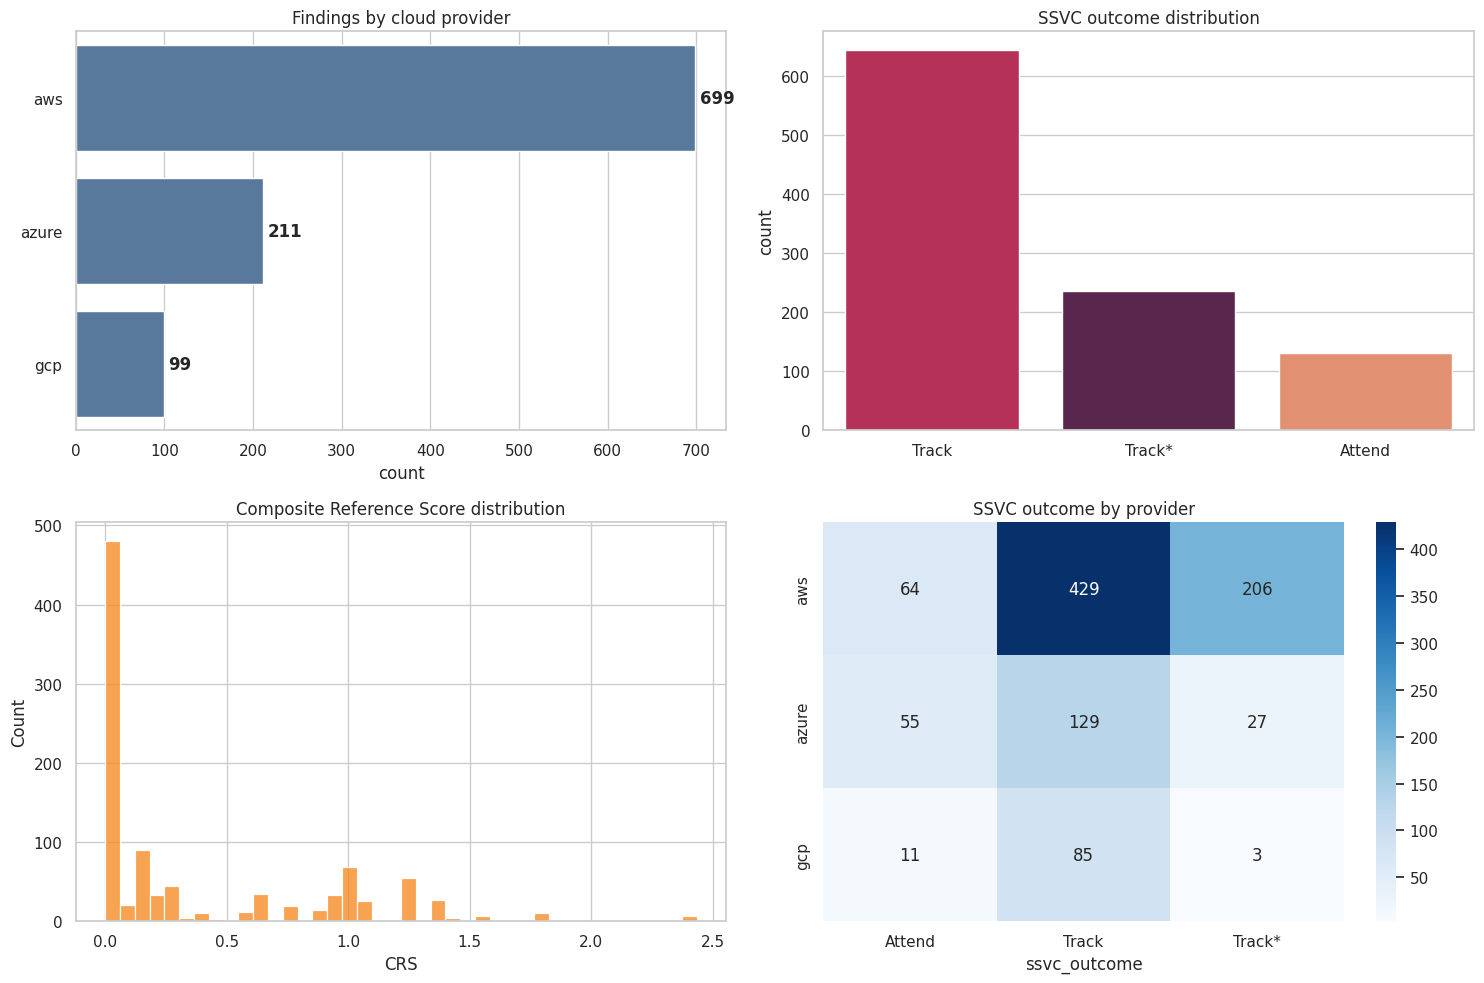

  mirrored -> figures/fig1_corpus_overview.png


In [10]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
sns.countplot(data=df, y="provider", ax=ax[0,0], color="#4C78A8",
              order=df["provider"].value_counts().index)
for i, v in enumerate(df["provider"].value_counts()):
    ax[0,0].text(v+5, i, str(v), va="center", fontweight="bold")
ax[0,0].set_title("Findings by cloud provider"); ax[0,0].set_ylabel("")

order = [o for o in ["Track","Track*","Attend","Act"] if o in set(df["ssvc_outcome"])]
sns.countplot(data=df, x="ssvc_outcome", ax=ax[0,1], palette="rocket", order=order, hue="ssvc_outcome", legend=False)
ax[0,1].set_title("SSVC outcome distribution"); ax[0,1].set_xlabel("")

sns.histplot(data=df, x="crs", bins=40, ax=ax[1,0], color="#F58518")
ax[1,0].set_title("Composite Reference Score distribution"); ax[1,0].set_xlabel("CRS")

sns.heatmap(pd.crosstab(df["provider"], df["ssvc_outcome"]), annot=True, fmt="d",
            cmap="Blues", ax=ax[1,1])
ax[1,1].set_title("SSVC outcome by provider"); ax[1,1].set_ylabel("")

plt.tight_layout(); plt.savefig(FIG/"fig1_corpus_overview.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig1_corpus_overview.png", "figures/fig1_corpus_overview.png")

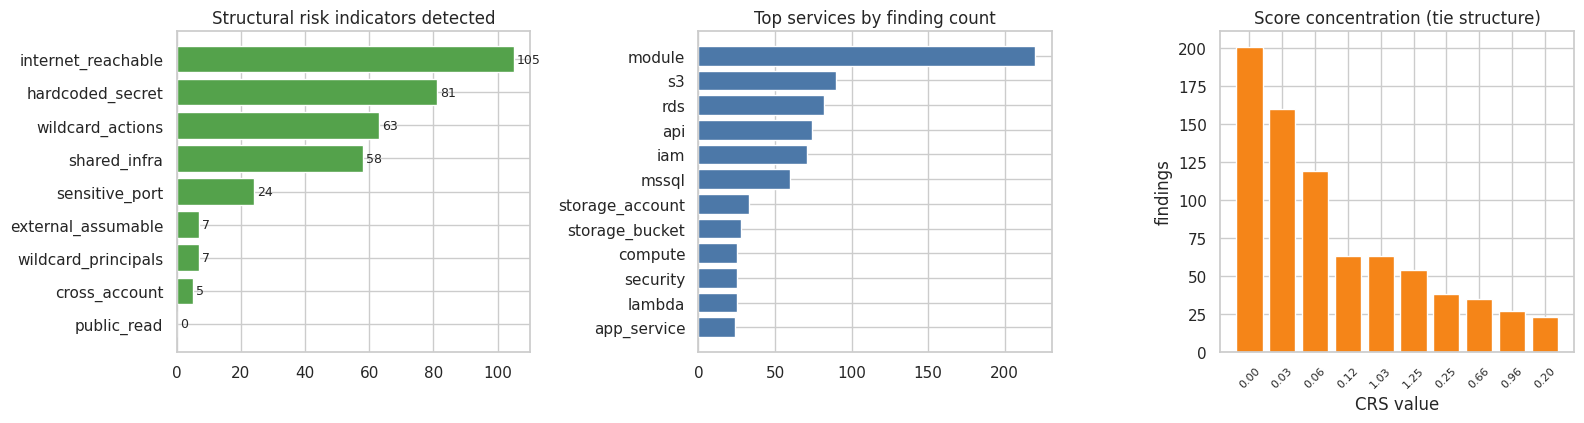

  mirrored -> figures/fig2_features.png


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
d2 = dens.sort_values("count")
ax[0].barh(d2.index, d2["count"], color="#54A24B")
for i, v in enumerate(d2["count"]): ax[0].text(v+1, i, str(v), va="center", fontsize=9)
ax[0].set_title("Structural risk indicators detected")

sv = df["service"].value_counts().head(12)
ax[1].barh(sv.index[::-1], sv.values[::-1], color="#4C78A8")
ax[1].set_title("Top services by finding count")

vc = df["crs"].value_counts().head(10)
ax[2].bar(range(len(vc)), vc.values, color="#F58518")
ax[2].set_xticks(range(len(vc))); ax[2].set_xticklabels([f"{v:.2f}" for v in vc.index], rotation=45, fontsize=8)
ax[2].set_xlabel("CRS value"); ax[2].set_ylabel("findings")
ax[2].set_title("Score concentration (tie structure)")

plt.tight_layout(); plt.savefig(FIG/"fig2_features.png", dpi=200, bbox_inches="tight"); plt.show()
mirror(FIG/"fig2_features.png", "figures/fig2_features.png")

## 9 · Export


In [12]:
with open(OUT/"findings_ufs.jsonl","w",encoding="utf-8") as fh:
    for f in findings:
        fh.write(json.dumps(f.model_dump(mode="json"), ensure_ascii=False)+"\n")
df.to_csv(OUT/"findings_features.csv", index=False)
try: df.to_parquet(OUT/"findings_features.parquet", index=False)
except Exception: pass

manifest = {
 "created_utc": datetime.now(timezone.utc).isoformat(),
 "schema_version": SCHEMA_VERSION,
 "mcasm_version": mcasm.__version__,
 "total_findings": len(findings),
 "distinct_resources": int(df["resource_id"].nunique()),
 "provider_distribution": df["provider"].value_counts().to_dict(),
 "ssvc_distribution": df["ssvc_outcome"].value_counts().to_dict(),
 "source_distribution": df["source_repo"].value_counts().to_dict(),
 "feature_density": dens["count"].to_dict(),
 "distinct_crs_values": int(df["crs"].nunique()),
 "largest_tie_group_pct": float(100*df["crs"].value_counts().iloc[0]/len(df)),
 "crs_weights": WEIGHTS,
 "sources": provenance,
 "coverage": coverage,
 "tool": "checkov", "scan_flags": "-o json --quiet (NOT --compact)",
 "limitations":[
   "Terraform interpolations are not resolved; unresolved references default to not-exposed, biasing exposure detection downward.",
   "Open-source Checkov supplies no severity or benchmark mappings; scanner_severity is null throughout.",
   "CNAPPgoat contributes no findings: it is written in Pulumi, which Checkov cannot parse. It is retained for its scenario taxonomy.",
   "Findings are per-check, so one resource may yield several. Resource-level aggregation happens in Notebook 02.",
   "IaC analysis is a proxy for runtime state; configuration drift is not captured.",
 ],
}
(OUT/"manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print(json.dumps({k:v for k,v in manifest.items() if k not in ("sources","coverage")},
                 indent=2, default=str))

{
  "created_utc": "2026-08-03T09:03:02.376607+00:00",
  "schema_version": "1.0.0",
  "mcasm_version": "1.2.0",
  "total_findings": 1009,
  "distinct_resources": 340,
  "provider_distribution": {
    "aws": 699,
    "azure": 211,
    "gcp": 99
  },
  "ssvc_distribution": {
    "Track": 643,
    "Track*": 236,
    "Attend": 130
  },
  "source_distribution": {
    "bridgecrewio/terragoat": 445,
    "BishopFox/iam-vulnerable": 269,
    "ine-labs/AWSGoat": 215,
    "ine-labs/GCPGoat": 43,
    "ine-labs/AzureGoat": 37
  },
  "feature_density": {
    "internet_reachable": 105,
    "sensitive_port": 24,
    "wildcard_actions": 63,
    "wildcard_principals": 7,
    "external_assumable": 7,
    "hardcoded_secret": 81,
    "public_read": 0,
    "cross_account": 5,
    "shared_infra": 58
  },
  "distinct_crs_values": 49,
  "largest_tie_group_pct": 19.920713577799802,
  "crs_weights": {
    "exposure": 0.3,
    "identity": 0.25,
    "data": 0.2,
    "blast": 0.15,
    "intel": 0.1
  },
  "tool": "

In [13]:
mirror(OUT, "ufs")
mirror(SCANS, "scans")
archive = shutil.make_archive("/content/mcasm_corpus_stage1", "zip", BASE)
mirror(archive, "mcasm_corpus_stage1.zip")
print(f"\narchive: {Path(archive).stat().st_size/1024**2:.1f} MiB")
if DRIVE: print(f"everything mirrored to {DRIVE}")

from google.colab import files
try: files.download(archive)
except Exception: print("browser download failed — retrieve from Drive")

  mirrored -> ufs
  mirrored -> scans
  mirrored -> mcasm_corpus_stage1.zip

archive: 203.9 MiB
everything mirrored to /content/drive/MyDrive/mcasm_stage1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10 · Sanity check

The top of this list should look alarming to a security practitioner. If it does not, the
feature extractors need work before proceeding.


In [14]:
top = sorted(findings, key=composite_reference_score, reverse=True)[:10]
for i, f in enumerate(top, 1):
    print(f"{i:2}. CRS={composite_reference_score(f):6.3f}  "
          f"[{ssvc_classify(f)['outcome']:7}]  {f.resource_id[:56]}")
    print(f"    {generate_justification(f)[:170]}")
    print()

 1. CRS= 2.435  [Attend ]  google_storage_bucket_iam_member.add_policy_role
    google_storage_bucket_iam_member.add_policy_role (gcp/storage_bucket) reachable from the internet; requires no authentication; is grantable to any principal; is reference

 2. CRS= 2.435  [Attend ]  google_storage_bucket_iam_member.add_policy_role2
    google_storage_bucket_iam_member.add_policy_role2 (gcp/storage_bucket) reachable from the internet; requires no authentication; is grantable to any principal; is referenc

 3. CRS= 2.405  [Attend ]  google_storage_bucket_iam_binding.allow_public_read
    google_storage_bucket_iam_binding.allow_public_read (gcp/storage_bucket) reachable from the internet; requires no authentication; is grantable to any principal; is refere

 4. CRS= 2.405  [Attend ]  google_storage_bucket_iam_member.function_member
    google_storage_bucket_iam_member.function_member (gcp/storage_bucket) reachable from the internet; requires no authentication; is grantable to any principal; is

---

**Next:** `02_corpus_b_prioritisation.ipynb` turns these findings into set-to-ranking
instances, which is the actual task the model is trained and evaluated on.

Send forward: `mcasm_corpus_stage1.zip` (also on Drive at `MyDrive/mcasm_stage1/`).
